# 06 · Forecast
**Where to Invest: Microsoft Growth Investment Analysis**

Goal: forecast revenue for fiscal Q2 FY27 (Oct–Dec 2026) with 80% and 95% intervals.
- **Model:** monthly revenue = trend + a fixed effect for each fiscal month (captures quarter-end billing and the
  strong Q2), fitted by least squares.
- **Back-test:** refit without the last two quarters (Apr–Sep 2026), forecast them, compare with actuals (MAPE).
- **Intervals** come from the spread of the back-test errors.
- **Cross-checks** (not model inputs): budget, the sales pipeline, and last year's growth.

Tools: SQL (DuckDB) view `v_forecast_input`; Python (pandas, numpy) for the model; matplotlib for the charts.

> **Synthetic data, calibrated to Microsoft's published results.** Generated by `data/generate.py`: totals by
> segment and quarter are close to Microsoft's reported figures; every record underneath them is invented.

In [1]:
import os
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook is run from the project root or from notebooks/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)

# The database and its views were built in 03_profitability.ipynb; here we only read them
con = duckdb.connect("data/finance.duckdb", read_only=True)


def billions(value):
    """Format USD as $12.34B."""
    return f"${value / 1_000_000_000:,.2f}B"


Z80, Z95 = 1.2816, 1.9600     # normal quantiles for 80% and 95% two-sided intervals

# One row per month, Jan 2024 - Dec 2026: 'train' (to Mar 2026), 'holdout' (Apr-Sep 2026), 'forecast' (Oct-Dec 2026)
series = con.sql("SELECT * FROM v_forecast_input ORDER BY month_start").df()
series["month_start"] = pd.to_datetime(series["month_start"])
series.style.format({
    **{c: billions for c in series.columns if c.endswith("_usd")},
    "month_start": lambda d: d.strftime("%Y-%m-%d"),
}, na_rep="–").hide(axis="index")

month_start,month_index,fiscal_year,fiscal_year_quarter,fiscal_period,revenue_usd,budget_revenue_usd,sample
2024-01-01,1,FY24,FY24-Q3,7,$11.96B,–,train
2024-02-01,2,FY24,FY24-Q3,8,$12.02B,–,train
2024-03-01,3,FY24,FY24-Q3,9,$37.66B,–,train
2024-04-01,4,FY24,FY24-Q4,10,$12.19B,–,train
2024-05-01,5,FY24,FY24-Q4,11,$12.58B,–,train
2024-06-01,6,FY24,FY24-Q4,12,$39.56B,–,train
2024-07-01,7,FY25,FY25-Q1,1,$12.60B,$20.49B,train
2024-08-01,8,FY25,FY25-Q1,2,$13.19B,$21.45B,train
2024-09-01,9,FY25,FY25-Q1,3,$39.50B,$21.55B,train
2024-10-01,10,FY25,FY25-Q2,4,$13.02B,$21.32B,train


## 1. The series to forecast

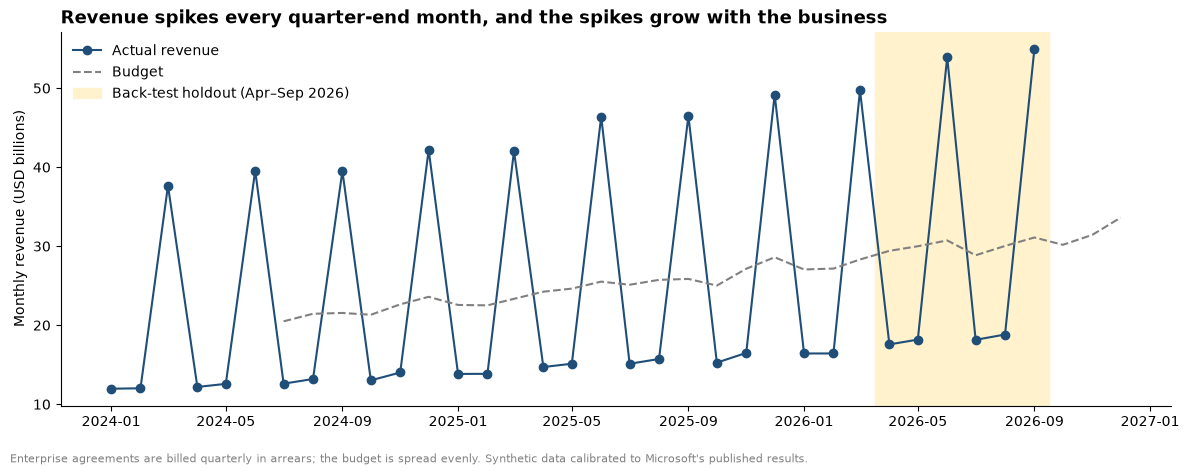

In [2]:
history = series[series["sample"] != "forecast"]
holdout = series[series["sample"] == "holdout"]

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(history["month_start"], history["revenue_usd"] / 1e9, marker="o", color="#1F4E79", label="Actual revenue")
ax.plot(series["month_start"], series["budget_revenue_usd"] / 1e9, color="grey", linestyle="--", label="Budget")
ax.axvspan(holdout["month_start"].min() - pd.Timedelta(days=15), holdout["month_start"].max() + pd.Timedelta(days=15),
           color="#FFF2CC", label="Back-test holdout (Apr–Sep 2026)")
ax.set_ylabel("Monthly revenue (USD billions)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Revenue spikes every quarter-end month, and the spikes grow with the business",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Enterprise agreements are billed quarterly in arrears; the budget is spread evenly. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

Revenue is billing, and enterprise agreements are billed quarterly in arrears, so every quarter-end month
(Sep, Dec, Mar, Jun) is about three times a normal month. A **fixed effect for each fiscal month** captures this
pattern. Because the spikes grow in proportion to the business, a model on the **logarithm** of revenue (constant
growth in %) should fit better than one on revenue itself (constant growth in dollars). The back-test decides.

## 2. Back-test: linear vs log-linear trend

Both models are fitted on Jan 2024 – Mar 2026 (27 months) and asked to forecast Apr – Sep 2026 (6 months).
MAPE = average of |actual − forecast| ÷ actual.

In [3]:
def design_matrix(df):
    """Columns: month index (trend) + one dummy per fiscal period (fiscal-month effects)."""
    trend = df["month_index"].astype(float).to_numpy()
    months = pd.get_dummies(df["fiscal_period"].astype(int), dtype=float)
    months = months.reindex(columns=range(1, 13), fill_value=0.0).to_numpy()
    return np.column_stack([trend, months])


def fit(df, log=False):
    """Least-squares coefficients; log=True fits log(revenue)."""
    y = df["revenue_usd"].to_numpy()
    y = np.log(y) if log else y
    coef, *_ = np.linalg.lstsq(design_matrix(df), y, rcond=None)
    return coef


def predict(coef, df, log=False):
    pred = design_matrix(df) @ coef
    return np.exp(pred) if log else pred


train = series[series["sample"] == "train"]
test = series[series["sample"] == "holdout"]

results = []
backtest = test[["month_start", "fiscal_year_quarter", "revenue_usd"]].copy()
for name, log in [("Linear trend", False), ("Log-linear trend", True)]:
    pred = predict(fit(train, log), test, log)
    backtest[name] = pred
    pct_error = (test["revenue_usd"].to_numpy() - pred) / test["revenue_usd"].to_numpy()
    quarter_actual = test.groupby("fiscal_year_quarter")["revenue_usd"].sum()
    quarter_pred = pd.Series(pred, index=test.index).groupby(test["fiscal_year_quarter"]).sum()
    results.append({
        "model": name,
        "MAPE (monthly)": np.mean(np.abs(pct_error)),
        "bias (mean error)": np.mean(pct_error),
        "RMSE % (monthly)": np.sqrt(np.mean(pct_error ** 2)),
        "MAPE (quarterly)": np.mean(np.abs((quarter_actual - quarter_pred) / quarter_actual)),
    })

accuracy = pd.DataFrame(results)
accuracy.style.format({c: "{:.1%}" for c in accuracy.columns if c != "model"}).hide(axis="index")

model,MAPE (monthly),bias (mean error),RMSE % (monthly),MAPE (quarterly)
Linear trend,8.3%,-1.0%,8.5%,3.7%
Log-linear trend,2.5%,2.2%,2.8%,1.4%


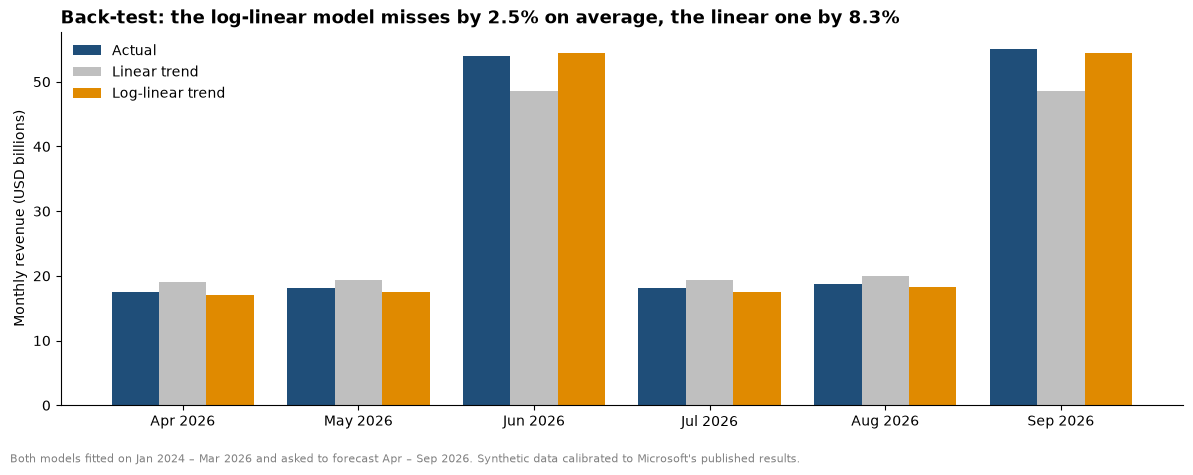

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = range(len(backtest))
w = 0.27
ax.bar([p - w for p in x], backtest["revenue_usd"] / 1e9, w, color="#1F4E79", label="Actual")
ax.bar(list(x), backtest["Linear trend"] / 1e9, w, color="#BFBFBF", label="Linear trend")
ax.bar([p + w for p in x], backtest["Log-linear trend"] / 1e9, w, color="#E08A00", label="Log-linear trend")
ax.set_xticks(list(x))
ax.set_xticklabels(backtest["month_start"].dt.strftime("%b %Y"))
ax.set_ylabel("Monthly revenue (USD billions)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Back-test: the log-linear model misses by {accuracy['MAPE (monthly)'].min():.1%} on average, "
             f"the linear one by {accuracy['MAPE (monthly)'].max():.1%}",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Both models fitted on Jan 2024 – Mar 2026 and asked to forecast Apr – Sep 2026. "
         "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings.**
- **Log-linear trend: MAPE 2.5%** monthly and 1.4% on quarterly totals. **Linear trend: MAPE 8.3%** monthly and
  3.7% quarterly. The linear model under-shoots every quarter-end spike and over-shoots normal months.
- The log-linear model is chosen. Its back-test errors are slightly positive on average (+2.2%): actuals came in
  a little **above** the forecast, because growth accelerated in 2026. The risk to the forecast is on the upside.

## 3. Q2 FY27 forecast with 80% and 95% intervals

The chosen model is refitted on all 33 months (Jan 2024 – Sep 2026) and projected for Oct–Dec 2026.
Intervals = forecast × (1 ± z × RMSE of the back-test errors), with z = 1.28 (80%) and 1.96 (95%).
The quarterly interval applies the same percentage to the quarter total, which is conservative: it assumes the
three months err in the same direction.

In [5]:
LOG = True                                            # log-linear model, chosen by the back-test
coef = fit(history, LOG)

future = series[series["sample"] == "forecast"].copy()
future["forecast_usd"] = predict(coef, future, LOG)

rmse = accuracy.loc[accuracy["model"] == "Log-linear trend", "RMSE % (monthly)"].iloc[0]
for level, z in [("80", Z80), ("95", Z95)]:
    future[f"low_{level}_usd"] = future["forecast_usd"] * (1 - z * rmse)
    future[f"high_{level}_usd"] = future["forecast_usd"] * (1 + z * rmse)

q2 = future[["forecast_usd", "low_80_usd", "high_80_usd", "low_95_usd", "high_95_usd", "budget_revenue_usd"]].sum()
print(f"Q2 FY27 forecast {billions(q2['forecast_usd'])} | "
      f"80%: {billions(q2['low_80_usd'])}–{billions(q2['high_80_usd'])} | "
      f"95%: {billions(q2['low_95_usd'])}–{billions(q2['high_95_usd'])} | "
      f"budget {billions(q2['budget_revenue_usd'])}")

forecast_table = future[["month_start", "fiscal_year_quarter", "forecast_usd",
                         "low_80_usd", "high_80_usd", "low_95_usd", "high_95_usd",
                         "budget_revenue_usd"]]

forecast_table.style.format({
    **{c: billions for c in forecast_table.columns if c.endswith("_usd")},
    "month_start": lambda d: d.strftime("%Y-%m-%d"),
}).hide(axis="index")

Q2 FY27 forecast $96.04B | 80%: $92.63B–$99.44B | 95%: $90.82B–$101.25B | budget $95.22B


month_start,fiscal_year_quarter,forecast_usd,low_80_usd,high_80_usd,low_95_usd,high_95_usd,budget_revenue_usd
2026-10-01,FY27-Q2,$18.09B,$17.45B,$18.73B,$17.11B,$19.07B,$30.18B
2026-11-01,FY27-Q2,$19.51B,$18.82B,$20.20B,$18.45B,$20.57B,$31.43B
2026-12-01,FY27-Q2,$58.44B,$56.37B,$60.51B,$55.27B,$61.61B,$33.62B


The budget is spread evenly across the quarter, while billing peaks in the quarter-end month, so compare at quarter level: forecast $96.0B vs budget $95.2B.

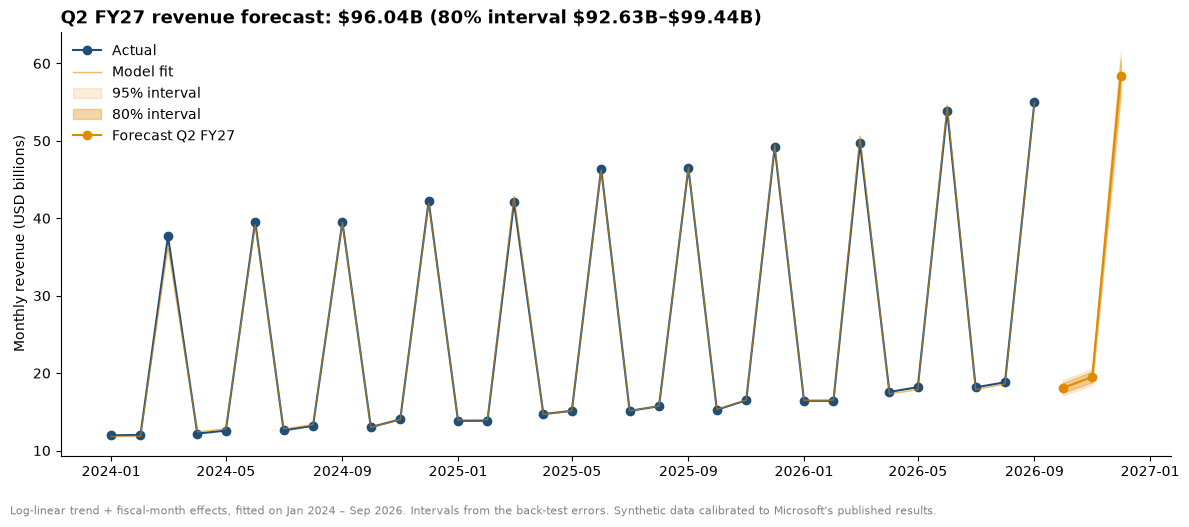

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(history["month_start"], history["revenue_usd"] / 1e9, marker="o", color="#1F4E79", label="Actual")
ax.plot(history["month_start"], predict(coef, history, LOG) / 1e9, color="#E08A00", linewidth=1, alpha=0.6,
        label="Model fit")
ax.fill_between(future["month_start"], future["low_95_usd"] / 1e9, future["high_95_usd"] / 1e9,
                color="#E08A00", alpha=0.15, label="95% interval")
ax.fill_between(future["month_start"], future["low_80_usd"] / 1e9, future["high_80_usd"] / 1e9,
                color="#E08A00", alpha=0.35, label="80% interval")
ax.plot(future["month_start"], future["forecast_usd"] / 1e9, marker="o", color="#E08A00", label="Forecast Q2 FY27")
ax.set_ylabel("Monthly revenue (USD billions)")
ax.legend(frameon=False, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
ax.set_title(f"Q2 FY27 revenue forecast: {billions(q2['forecast_usd'])} "
             f"(80% interval {billions(q2['low_80_usd'])}–{billions(q2['high_80_usd'])})",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.04, "Log-linear trend + fiscal-month effects, fitted on Jan 2024 – Sep 2026. Intervals from the "
         "back-test errors. Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

## 4. Cross-checks

Three independent estimates of Q2 FY27 revenue, shown beside the forecast (not used as model inputs):
- **Budget:** the FY27 plan for Oct–Dec 2026.
- **Run-rate + weighted pipeline:** Q1 FY27 revenue, plus the revenue that open deals closing in Q2 would add in
  the quarter, weighted by their probability (`v_pipeline_coverage`).
- **Last year's growth:** Q2 FY26 revenue × the year-on-year growth of Q1 FY27.

estimate,q2_fy27_revenue_usd,vs_forecast,inside_80
Forecast (this model),$96.04B,+0.0%,Yes
Budget,$95.22B,-0.8%,Yes
Run-rate + weighted pipeline,$94.02B,-2.1%,Yes
Q2 FY26 × FY27 Q1 year-on-year growth,$96.24B,+0.2%,Yes


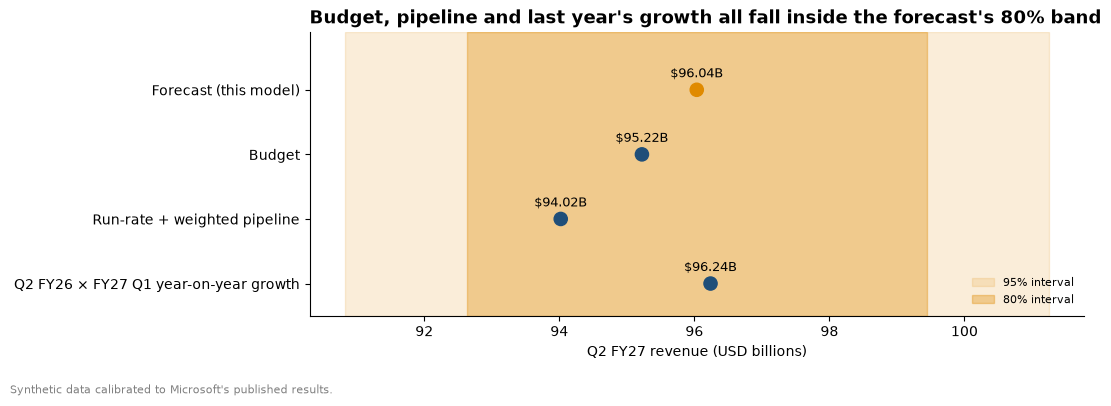

In [7]:
quarterly = con.sql("""
    SELECT fiscal_year_quarter, SUM(revenue_usd) AS revenue_usd
    FROM v_forecast_input
    WHERE sample <> 'forecast'
    GROUP BY fiscal_year_quarter
    ORDER BY fiscal_year_quarter
""").df()
pipeline = con.sql("SELECT * FROM v_pipeline_coverage WHERE product_line = 'Total'").df().iloc[0]
q2_last_year = quarterly.loc[quarterly["fiscal_year_quarter"] == "FY26-Q2", "revenue_usd"].iloc[0]
q1_now = quarterly.loc[quarterly["fiscal_year_quarter"] == "FY27-Q1", "revenue_usd"].iloc[0]
q1_last_year = quarterly.loc[quarterly["fiscal_year_quarter"] == "FY26-Q1", "revenue_usd"].iloc[0]

cross_checks = pd.DataFrame({
    "estimate": ["Forecast (this model)", "Budget", "Run-rate + weighted pipeline",
                 "Q2 FY26 × FY27 Q1 year-on-year growth"],
    "q2_fy27_revenue_usd": [q2["forecast_usd"], q2["budget_revenue_usd"],
                            pipeline["q1_actual_revenue_usd"] + pipeline["weighted_revenue_in_quarter_usd"],
                            q2_last_year * q1_now / q1_last_year],
})
cross_checks["vs_forecast"] = cross_checks["q2_fy27_revenue_usd"] / q2["forecast_usd"] - 1
cross_checks["inside_80"] = cross_checks["q2_fy27_revenue_usd"].between(q2["low_80_usd"], q2["high_80_usd"])

display(cross_checks.style.format({
    "q2_fy27_revenue_usd": billions,
    "vs_forecast": "{:+.1%}",
    "inside_80": lambda v: "Yes" if v else "No",
}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(11, 3.8))
ax.axvspan(q2["low_95_usd"] / 1e9, q2["high_95_usd"] / 1e9, color="#E08A00", alpha=0.15, label="95% interval")
ax.axvspan(q2["low_80_usd"] / 1e9, q2["high_80_usd"] / 1e9, color="#E08A00", alpha=0.35, label="80% interval")
y = range(len(cross_checks))
colors = ["#E08A00"] + ["#1F4E79"] * (len(cross_checks) - 1)
ax.scatter(cross_checks["q2_fy27_revenue_usd"] / 1e9, y, color=colors, s=90, zorder=3)
for i, row in cross_checks.iterrows():
    ax.annotate(billions(row["q2_fy27_revenue_usd"]), (row["q2_fy27_revenue_usd"] / 1e9, i),
                xytext=(0, 9), textcoords="offset points", ha="center", fontsize=9)
ax.set_yticks(list(y))
ax.set_yticklabels(cross_checks["estimate"])
ax.set_ylim(len(cross_checks) - 0.5, -0.9)     # reversed axis with room for the labels
ax.set_xlabel("Q2 FY27 revenue (USD billions)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
ax.set_title("Budget, pipeline and last year's growth all fall inside the forecast's 80% band",
             loc="left", fontsize=13, fontweight="bold")
fig.text(0.01, -0.05, "Synthetic data calibrated to Microsoft's published results.", fontsize=8, color="grey")
plt.tight_layout()
plt.show()

**Findings.**
- **Q2 FY27 revenue forecast: $96.0B**, with an 80% interval of **$92.6B – $99.4B** and a 95% interval of
  **$90.8B – $101.2B**. By month: October $18.1B, November $19.5B, December $58.4B (quarter-end billing).
- All three cross-checks fall inside the 80% band:
  - **Budget:** $95.2B (−0.8% vs the forecast).
  - **Last year's growth:** $96.2B (+0.2%).
  - **Run-rate + weighted pipeline:** $94.0B (−2.1%). This is the lowest estimate, because the pipeline covers only 63% of the gap between Q1 run-rate and the Q2 budget (`v_pipeline_coverage`).
- Back-test accuracy: **MAPE 2.5%** monthly (1.4% on quarterly totals).

## Summary
- **Expect:** Q2 FY27 revenue of **$96.0B** (80% interval $92.6B – $99.4B); back-test MAPE 2.5%.
- **Use as guidance base case:** $96.0B is above the $95.2B budget; the back-test bias is positive, so the
  risk is to the upside, but the pipeline shortfall says new business must close for the top half of the range.
- **Watch:** actuals outside the 80% band two months in a row would mean the model no longer holds (a price
  change, outage or capacity shortage).
- **Next:** the Tableau dashboard and the one-page CFO summary.

In [8]:
con.close()   # releases data/finance.duckdb